In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
base_path = '/content/drive/MyDrive/chronic-disease-project/'
print(os.listdir(base_path))

In [ ]:
!pip install xgboost lightgbm shap -q

import pandas as pd
import numpy as np

In [ ]:
df_diabetes = pd.read_csv(base_path + 'diabetes_binary_health_indicators_BRFSS2015.csv')
df_heart = pd.read_csv(base_path + 'heart.csv')
df_kidney = pd.read_csv(base_path + 'kidney_disease.csv')

print("Diabetes:", df_diabetes.shape)
print("Heart:", df_heart.shape)
print("Kidney:", df_kidney.shape)

print(df_diabetes.columns.tolist())
print(df_heart.columns.tolist())
print(df_kidney.columns.tolist())

In [ ]:
print(df_diabetes.isnull().sum().sum())  # usually 0
X_diabetes = df_diabetes.drop('Diabetes_binary', axis=1)
y_diabetes = df_diabetes['Diabetes_binary']

In [ ]:
print(df_heart.isnull().sum().sum())

df_heart_encoded = pd.get_dummies(
    df_heart,
    columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'],
    drop_first=True
)

X_heart = df_heart_encoded.drop('HeartDisease', axis=1)
y_heart = df_heart_encoded['HeartDisease']

print(X_heart.shape)
print(X_heart.columns.tolist())

In [ ]:
# id column hata do
df_kidney = df_kidney.drop('id', axis=1)

# saare object (text) columns mein extra spaces/tabs hote hain — clean karo
obj_cols = df_kidney.select_dtypes(include='object').columns
for col in obj_cols:
    df_kidney[col] = df_kidney[col].astype(str).str.strip()

# 'pcv', 'wc', 'rc' numeric hone chahiye par CSV mein text ban gaye hain — convert karo
numeric_like = ['pcv', 'wc', 'rc']
for col in numeric_like:
    df_kidney[col] = pd.to_numeric(df_kidney[col], errors='coerce')

print(df_kidney.isnull().sum())
print(df_kidney.dtypes)
print(df_kidney['classification'].unique())

In [ ]:
# "nan" string ko wapas asli NaN banao
df_kidney[obj_cols] = df_kidney[obj_cols].replace('nan', np.nan)

print(df_kidney.isnull().sum())

In [ ]:
# numeric columns: median se fill karo (outliers ke against robust hai)
numeric_cols = df_kidney.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    df_kidney[col] = df_kidney[col].fillna(df_kidney[col].median())

# categorical columns: mode (sabse common value) se fill karo
categorical_cols = df_kidney.select_dtypes(include='object').columns.drop('classification')
for col in categorical_cols:
    df_kidney[col] = df_kidney[col].fillna(df_kidney[col].mode()[0])

print(df_kidney.isnull().sum().sum())  # ab 0 aana chahiye

In [ ]:
# target encode: ckd=1, notckd=0
df_kidney['classification'] = df_kidney['classification'].map({'ckd': 1, 'notckd': 0})

# baaki categorical columns one-hot encode
df_kidney_encoded = pd.get_dummies(df_kidney, columns=list(categorical_cols), drop_first=True)

X_kidney = df_kidney_encoded.drop('classification', axis=1)
y_kidney = df_kidney_encoded['classification']

print(X_kidney.shape)
print(y_kidney.value_counts())

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
import xgboost as xgb
import lightgbm as lgb
import shap
import warnings
warnings.filterwarnings('ignore')

def train_ensemble(X, y, disease_name, test_size=0.2):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    base_learners = [
        ('rf', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')),
        ('xgb', xgb.XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss')),
        ('lgb', lgb.LGBMClassifier(n_estimators=200, random_state=42, verbose=-1))
    ]

    stack_model = StackingClassifier(
        estimators=base_learners,
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5
    )

    stack_model.fit(X_train, y_train)
    y_pred = stack_model.predict(X_test)
    y_proba = stack_model.predict_proba(X_test)[:, 1]

    print(f"\n===== {disease_name} Results =====")
    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
    print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

    return stack_model, X_train, X_test, y_train, y_test

In [ ]:
model_diabetes, Xtr_d, Xte_d, ytr_d, yte_d = train_ensemble(X_diabetes, y_diabetes, "Diabetes")

In [ ]:
def train_ensemble(X, y, disease_name, test_size=0.2):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)

    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    base_learners = [
        ('rf', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')),
        ('xgb', xgb.XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss', scale_pos_weight=scale_pos_weight)),
        ('lgb', lgb.LGBMClassifier(n_estimators=200, random_state=42, verbose=-1, class_weight='balanced'))
    ]

    stack_model = StackingClassifier(
        estimators=base_learners,
        final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced'),
        cv=5
    )

    stack_model.fit(X_train, y_train)
    y_pred = stack_model.predict(X_test)
    y_proba = stack_model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    print("\n===== " + disease_name + " Results =====")
    print("Accuracy: ", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall:   ", round(rec, 4))
    print("F1-score: ", round(f1, 4))
    print("ROC-AUC:  ", round(auc, 4))

    return stack_model, X_train, X_test, y_train, y_test

In [ ]:
model_diabetes, Xtr_d, Xte_d, ytr_d, yte_d = train_ensemble(X_diabetes, y_diabetes, "Diabetes")


===== Diabetes Results =====
Accuracy:  0.7256
Precision: 0.3093
Recall:    0.7862
F1-score:  0.444
ROC-AUC:   0.8264


In [ ]:
import joblib
import os

save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'
os.makedirs(save_path, exist_ok=True)

# trained diabetes model save karo
joblib.dump(model_diabetes, save_path + 'model_diabetes.pkl')

# preprocessed train/test data bhi save kar do, taaki dobara preprocessing na karni pade
joblib.dump((Xtr_d, Xte_d, ytr_d, yte_d), save_path + 'diabetes_split.pkl')

# preprocessed X/y teeno diseases ke liye bhi save kar do
joblib.dump((X_diabetes, y_diabetes), save_path + 'diabetes_data.pkl')
joblib.dump((X_heart, y_heart), save_path + 'heart_data.pkl')
joblib.dump((X_kidney, y_kidney), save_path + 'kidney_data.pkl')

print("Saved successfully!")
print(os.listdir(save_path))

Saved successfully!
['model_diabetes.pkl', 'diabetes_split.pkl', 'diabetes_data.pkl', 'kidney_data.pkl', 'heart_data.pkl', 'model_heart.pkl', 'heart_split.pkl', 'model_kidney.pkl', 'kidney_split.pkl']


In [ ]:
import joblib
import os

save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'
os.makedirs(save_path, exist_ok=True)

joblib.dump(model_diabetes, save_path + 'model_diabetes.pkl')
joblib.dump((Xtr_d, Xte_d, ytr_d, yte_d), save_path + 'diabetes_split.pkl')
joblib.dump((X_diabetes, y_diabetes), save_path + 'diabetes_data.pkl')
joblib.dump((X_heart, y_heart), save_path + 'heart_data.pkl')
joblib.dump((X_kidney, y_kidney), save_path + 'kidney_data.pkl')

print("Saved successfully!")

KeyboardInterrupt: 

In [ ]:
model_heart, Xtr_h, Xte_h, ytr_h, yte_h = train_ensemble(X_heart, y_heart, "Heart Disease")

In [ ]:
joblib.dump(model_heart, save_path + 'model_heart.pkl')
joblib.dump((Xtr_h, Xte_h, ytr_h, yte_h), save_path + 'heart_split.pkl')
print("Heart model saved!")

In [ ]:
model_kidney, Xtr_k, Xte_k, ytr_k, yte_k = train_ensemble(X_kidney, y_kidney, "Kidney Disease")

In [ ]:
joblib.dump(model_kidney, save_path + 'model_kidney.pkl')
joblib.dump((Xtr_k, Xte_k, ytr_k, yte_k), save_path + 'kidney_split.pkl')
print("Kidney model saved!")

In [ ]:
import pandas as pd

# RF ka feature importance nikaalo stacking model ke andar se
rf_model = model_kidney.named_estimators_['rf']
importances = pd.Series(rf_model.feature_importances_, index=X_kidney.columns)
importances.sort_values(ascending=False).head(10)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install xgboost lightgbm shap -q

import pandas as pd
import numpy as np
import joblib
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
import xgboost as xgb
import lightgbm as lgb
import shap
import warnings
warnings.filterwarnings('ignore')

In [ ]:
save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'

model_diabetes = joblib.load(save_path + 'model_diabetes.pkl')
Xtr_d, Xte_d, ytr_d, yte_d = joblib.load(save_path + 'diabetes_split.pkl')
X_diabetes, y_diabetes = joblib.load(save_path + 'diabetes_data.pkl')

model_heart = joblib.load(save_path + 'model_heart.pkl')
Xtr_h, Xte_h, ytr_h, yte_h = joblib.load(save_path + 'heart_split.pkl')
X_heart, y_heart = joblib.load(save_path + 'heart_data.pkl')

model_kidney = joblib.load(save_path + 'model_kidney.pkl')
Xtr_k, Xte_k, ytr_k, yte_k = joblib.load(save_path + 'kidney_split.pkl')
X_kidney, y_kidney = joblib.load(save_path + 'kidney_data.pkl')

# original df_kidney bhi chahiye duplicate check ke liye
df_kidney = pd.read_csv('/content/drive/MyDrive/chronic-disease-project/datasets/kidney_disease.csv')

print("Sab kuch load ho gaya!")

EOFError: 

In [ ]:
import os
save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'
for f in os.listdir(save_path):
    size = os.path.getsize(save_path + f)
    print(f, "-", size, "bytes")

model_diabetes.pkl - 988535008 bytes
diabetes_split.pkl - 52767612 bytes
diabetes_data.pkl - 46678647 bytes
kidney_data.pkl - 57492 bytes
heart_data.pkl - 69010 bytes
model_heart.pkl - 5105510 bytes
heart_split.pkl - 92091 bytes
model_kidney.pkl - 995834 bytes
kidney_split.pkl - 68410 bytes


In [ ]:
drive.flush_and_unmount()

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import time
time.sleep(10)

model_diabetes = joblib.load(save_path + 'model_diabetes.pkl')
print("Loaded successfully!")

EOFError: 

In [ ]:
import shutil
shutil.copy(save_path + 'model_diabetes.pkl', '/content/model_diabetes.pkl')

import time
time.sleep(5)

model_diabetes = joblib.load('/content/model_diabetes.pkl')
print("Loaded successfully!")

EOFError: 

In [ ]:
print('X_diabetes' in dir())

True


In [ ]:
df_diabetes = pd.read_csv('/content/drive/MyDrive/chronic-disease-project/diabetes_binary_health_indicators_BRFSS2015.csv')
X_diabetes = df_diabetes.drop('Diabetes_binary', axis=1)
y_diabetes = df_diabetes['Diabetes_binary']

In [ ]:
def train_ensemble(X, y, disease_name, test_size=0.2):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)

    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    base_learners = [
        ('rf', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=-1)),
        ('xgb', xgb.XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss', scale_pos_weight=scale_pos_weight)),
        ('lgb', lgb.LGBMClassifier(n_estimators=200, random_state=42, verbose=-1, class_weight='balanced'))
    ]

    stack_model = StackingClassifier(
        estimators=base_learners,
        final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced'),
        cv=5,
        n_jobs=-1
    )

    stack_model.fit(X_train, y_train)
    y_pred = stack_model.predict(X_test)
    y_proba = stack_model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    print("\n===== " + disease_name + " Results =====")
    print("Accuracy: ", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall:   ", round(rec, 4))
    print("F1-score: ", round(f1, 4))
    print("ROC-AUC:  ", round(auc, 4))

    return stack_model, X_train, X_test, y_train, y_test

In [ ]:
model_diabetes, Xtr_d, Xte_d, ytr_d, yte_d = train_ensemble(X_diabetes, y_diabetes, "Diabetes")

NameError: name 'train_ensemble' is not defined

In [ ]:
print('X_diabetes' in dir())
print('train_ensemble' in dir())

False
False


In [ ]:
import pandas as pd
import numpy as np
import joblib
import os
import time
import shutil
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

In [ ]:
!pip install xgboost lightgbm -q

In [ ]:
df_diabetes = pd.read_csv('/content/drive/MyDrive/chronic-disease-project/diabetes_binary_health_indicators_BRFSS2015.csv')
X_diabetes = df_diabetes.drop('Diabetes_binary', axis=1)
y_diabetes = df_diabetes['Diabetes_binary']

In [ ]:
def train_ensemble(X, y, disease_name, test_size=0.2):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)

    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    base_learners = [
        ('rf', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=-1)),
        ('xgb', xgb.XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss', scale_pos_weight=scale_pos_weight)),
        ('lgb', lgb.LGBMClassifier(n_estimators=200, random_state=42, verbose=-1, class_weight='balanced'))
    ]

    stack_model = StackingClassifier(
        estimators=base_learners,
        final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced'),
        cv=5,
        n_jobs=-1
    )

    stack_model.fit(X_train, y_train)
    y_pred = stack_model.predict(X_test)
    y_proba = stack_model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    print("\n===== " + disease_name + " Results =====")
    print("Accuracy: ", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall:   ", round(rec, 4))
    print("F1-score: ", round(f1, 4))
    print("ROC-AUC:  ", round(auc, 4))

    return stack_model, X_train, X_test, y_train, y_test

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
import lightgbm as lgb

In [ ]:
def train_ensemble(X, y, disease_name, test_size=0.2):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)

    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    base_learners = [
        ('rf', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=-1)),
        ('xgb', xgb.XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss', scale_pos_weight=scale_pos_weight)),
        ('lgb', lgb.LGBMClassifier(n_estimators=200, random_state=42, verbose=-1, class_weight='balanced'))
    ]

    stack_model = StackingClassifier(
        estimators=base_learners,
        final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced'),
        cv=5,
        n_jobs=-1
    )

    stack_model.fit(X_train, y_train)
    y_pred = stack_model.predict(X_test)
    y_proba = stack_model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    print("\n===== " + disease_name + " Results =====")
    print("Accuracy: ", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall:   ", round(rec, 4))
    print("F1-score: ", round(f1, 4))
    print("ROC-AUC:  ", round(auc, 4))

    return stack_model, X_train, X_test, y_train, y_test

In [ ]:
model_diabetes, Xtr_d, Xte_d, ytr_d, yte_d = train_ensemble(X_diabetes, y_diabetes, "Diabetes")


===== Diabetes Results =====
Accuracy:  0.7256
Precision: 0.3093
Recall:    0.7862
F1-score:  0.444
ROC-AUC:   0.8264


In [ ]:
save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'

# pehle local Colab disk pe save karo
joblib.dump(model_diabetes, '/content/model_diabetes.pkl')

# verify karo local file sahi se load ho rahi hai
test_load = joblib.load('/content/model_diabetes.pkl')
print("Local save verified!")

# ab Drive pe copy karo
shutil.copy('/content/model_diabetes.pkl', save_path + 'model_diabetes.pkl')
print("Copied to Drive!")

# thoda wait karo Drive sync ke liye
time.sleep(10)

# Drive se load karke double-check karo
verify = joblib.load(save_path + 'model_diabetes.pkl')
print("Drive save verified successfully!")

Local save verified!
Copied to Drive!
Drive save verified successfully!


In [ ]:
joblib.dump((Xtr_d, Xte_d, ytr_d, yte_d), '/content/diabetes_split.pkl')
shutil.copy('/content/diabetes_split.pkl', save_path + 'diabetes_split.pkl')
time.sleep(5)
verify_split = joblib.load(save_path + 'diabetes_split.pkl')
print("Split data verified successfully!")

Split data verified successfully!


In [ ]:
# heart model load try karo
try:
    model_heart = joblib.load(save_path + 'model_heart.pkl')
    Xtr_h, Xte_h, ytr_h, yte_h = joblib.load(save_path + 'heart_split.pkl')
    X_heart, y_heart = joblib.load(save_path + 'heart_data.pkl')
    print("Heart files loaded successfully!")
except Exception as e:
    print("Heart load FAILED:", e)

# kidney model load try karo
try:
    model_kidney = joblib.load(save_path + 'model_kidney.pkl')
    Xtr_k, Xte_k, ytr_k, yte_k = joblib.load(save_path + 'kidney_split.pkl')
    X_kidney, y_kidney = joblib.load(save_path + 'kidney_data.pkl')
    print("Kidney files loaded successfully!")
except Exception as e:
    print("Kidney load FAILED:", e)

Heart files loaded successfully!
Kidney files loaded successfully!


In [ ]:
rf_model = model_kidney.named_estimators_['rf']
importances = pd.Series(rf_model.feature_importances_, index=X_kidney.columns)
print(importances.sort_values(ascending=False).head(10))

hemo       0.212467
pcv        0.156493
sc         0.142344
sg         0.127433
rc         0.084308
htn_yes    0.064191
al         0.048143
dm_yes     0.035742
bgr        0.023070
bu         0.022058
dtype: float64


In [ ]:
df_kidney_check = pd.read_csv('/content/drive/MyDrive/chronic-disease-project/kidney_disease.csv')
print("Duplicate rows:", df_kidney_check.duplicated().sum())

Duplicate rows: 0


In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model_kidney, X_kidney, y_kidney, cv=5, scoring='roc_auc')
print("CV ROC-AUC scores:", cv_scores)
print("Mean CV ROC-AUC:", cv_scores.mean())

CV ROC-AUC scores: [1.         1.         0.99866667 1.         1.        ]
Mean CV ROC-AUC: 0.9997333333333334


In [ ]:
!pip install shap -q
import shap

In [ ]:
explainer_kidney = shap.TreeExplainer(model_kidney.named_estimators_['rf'])
shap_values_kidney = explainer_kidney.shap_values(Xte_k)

print(type(shap_values_kidney))
if isinstance(shap_values_kidney, list):
    print(len(shap_values_kidney))

<class 'numpy.ndarray'>


In [ ]:
print(shap_values_kidney.shape)
print(Xte_k.shape)

(80, 24, 2)
(80, 24)


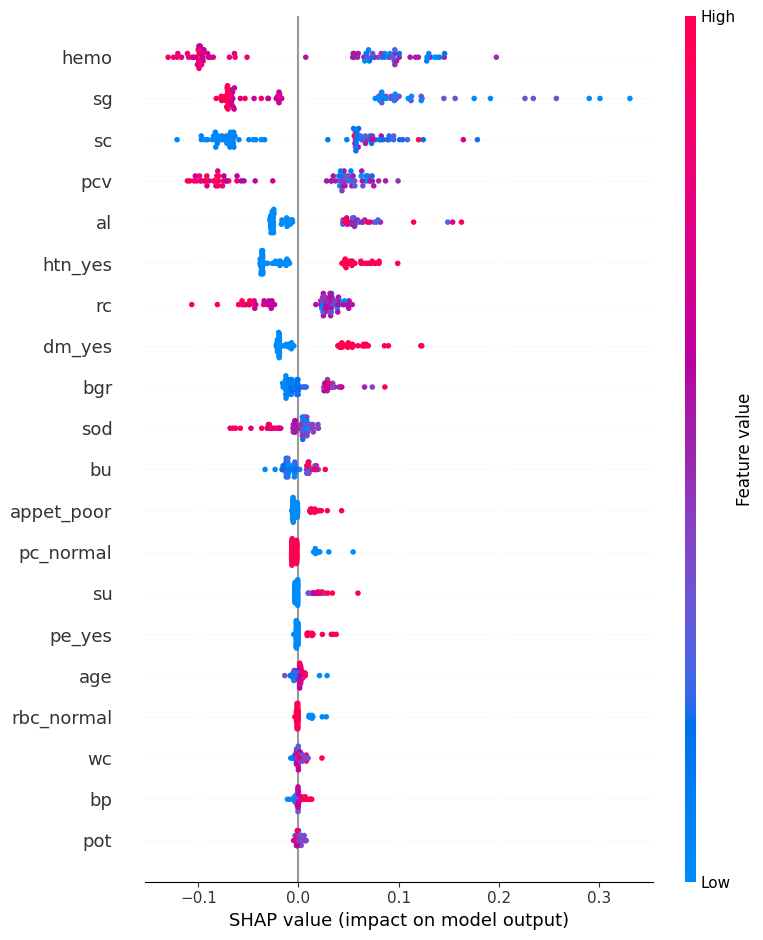

In [ ]:
shap_values_kidney_class1 = shap_values_kidney[:, :, 1]

shap.summary_plot(shap_values_kidney_class1, Xte_k, show=True)

In [ ]:
def get_shap_values(model, X_test):
    explainer = shap.TreeExplainer(model.named_estimators_['rf'])
    shap_values = explainer.shap_values(X_test)

    if len(shap_values.shape) == 3:
        shap_values = shap_values[:, :, 1]  # class 1 (positive) ka slice

    return shap_values

In [ ]:
import matplotlib.pyplot as plt

shap.summary_plot(shap_values_kidney_class1, Xte_k, show=False)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shap_kidney_summary.png', dpi=300, bbox_inches='tight')
plt.close()
print("Kidney SHAP plot saved!")

Kidney SHAP plot saved!


In [ ]:
def get_shap_values(model, X_test):
    explainer = shap.TreeExplainer(model.named_estimators_['rf'])
    shap_values = explainer.shap_values(X_test)

    if len(shap_values.shape) == 3:
        shap_values = shap_values[:, :, 1]

    return shap_values

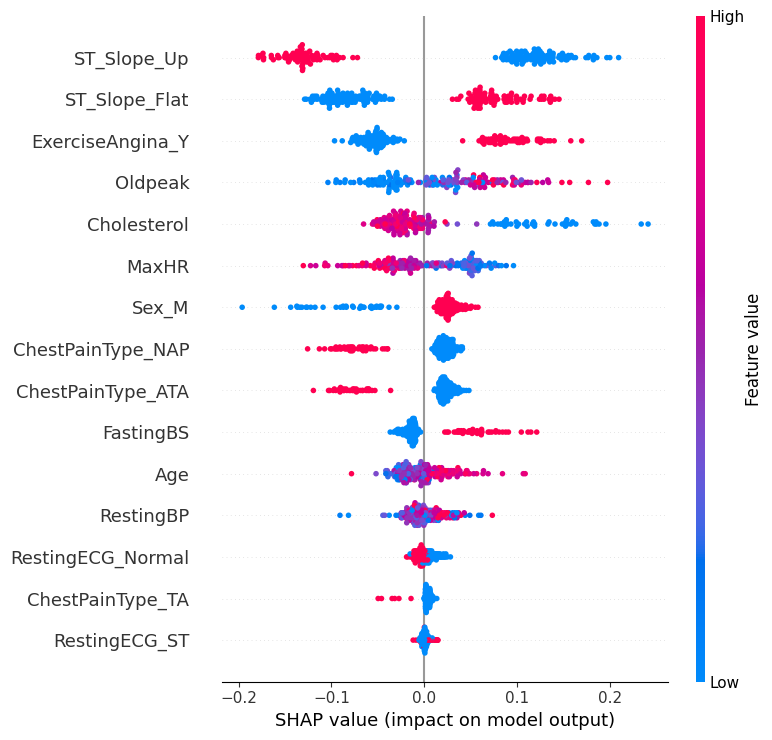

In [ ]:
shap_values_heart = get_shap_values(model_heart, Xte_h)
shap.summary_plot(shap_values_heart, Xte_h, show=False)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shap_heart_summary.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shap_heart_summary.png', dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
import numpy as np

sample_idx = np.random.choice(Xte_d.shape[0], 500, replace=False)
Xte_d_sample = Xte_d.iloc[sample_idx] if hasattr(Xte_d, 'iloc') else Xte_d[sample_idx]

shap_values_diabetes = get_shap_values(model_diabetes, Xte_d_sample)

shap.summary_plot(shap_values_diabetes, Xte_d_sample, show=False)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shap_diabetes_summary.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shap_heart_summary.png', dpi=300, bbox_inches='tight')
print("Heart SHAP plot saved!")


In [ ]:
!pip install xgboost lightgbm shap -q

import pandas as pd
import numpy as np
import joblib
import os
import time
import shutil
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
import lightgbm as lgb
import shap
import warnings
warnings.filterwarnings('ignore')

In [ ]:
save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'

model_diabetes = joblib.load(save_path + 'model_diabetes.pkl')
Xtr_d, Xte_d, ytr_d, yte_d = joblib.load(save_path + 'diabetes_split.pkl')

model_heart = joblib.load(save_path + 'model_heart.pkl')
Xtr_h, Xte_h, ytr_h, yte_h = joblib.load(save_path + 'heart_split.pkl')
X_heart, y_heart = joblib.load(save_path + 'heart_data.pkl')

model_kidney = joblib.load(save_path + 'model_kidney.pkl')
Xtr_k, Xte_k, ytr_k, yte_k = joblib.load(save_path + 'kidney_split.pkl')
X_kidney, y_kidney = joblib.load(save_path + 'kidney_data.pkl')

print("Sab models aur data load ho gaye!")

Sab models aur data load ho gaye!


In [ ]:
def get_shap_values(model, X_test):
    explainer = shap.TreeExplainer(model.named_estimators_['rf'])
    shap_values = explainer.shap_values(X_test)

    if len(shap_values.shape) == 3:
        shap_values = shap_values[:, :, 1]

    return shap_values

In [ ]:
sample_idx = np.random.choice(Xte_d.shape[0], 200, replace=False)
Xte_d_sample = Xte_d.iloc[sample_idx] if hasattr(Xte_d, 'iloc') else Xte_d[sample_idx]

shap_values_diabetes = get_shap_values(model_diabetes, Xte_d_sample)

shap.summary_plot(shap_values_diabetes, Xte_d_sample, show=False)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shap_diabetes_summary.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install xgboost lightgbm shap -q

import pandas as pd
import numpy as np
import joblib
import os
import time
import shutil
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
import lightgbm as lgb
import shap
import warnings
warnings.filterwarnings('ignore')

In [ ]:
save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'

model_diabetes = joblib.load(save_path + 'model_diabetes.pkl')
Xtr_d, Xte_d, ytr_d, yte_d = joblib.load(save_path + 'diabetes_split.pkl')

model_heart = joblib.load(save_path + 'model_heart.pkl')
Xtr_h, Xte_h, ytr_h, yte_h = joblib.load(save_path + 'heart_split.pkl')
X_heart, y_heart = joblib.load(save_path + 'heart_data.pkl')

model_kidney = joblib.load(save_path + 'model_kidney.pkl')
Xtr_k, Xte_k, ytr_k, yte_k = joblib.load(save_path + 'kidney_split.pkl')
X_kidney, y_kidney = joblib.load(save_path + 'kidney_data.pkl')

print("Sab models aur data load ho gaye!")

Sab models aur data load ho gaye!


In [ ]:
def get_shap_values(model, X_test):
    explainer = shap.TreeExplainer(model.named_estimators_['rf'])
    shap_values = explainer.shap_values(X_test)

    if len(shap_values.shape) == 3:
        shap_values = shap_values[:, :, 1]

    return shap_values

In [ ]:
import time
start = time.time()

sample_idx = np.random.choice(Xte_d.shape[0], 20, replace=False)
Xte_d_sample_small = Xte_d.iloc[sample_idx] if hasattr(Xte_d, 'iloc') else Xte_d[sample_idx]

shap_values_test = get_shap_values(model_diabetes, Xte_d_sample_small)

print("Time taken:", time.time() - start, "seconds")

Time taken: 235.39060068130493 seconds


In [ ]:
print('Xte_d' in dir())
print('model_diabetes' in dir())

True
True


In [ ]:
import time

sample_idx = np.random.choice(Xte_d.shape[0], 100, replace=False)
Xte_d_sample = Xte_d.iloc[sample_idx] if hasattr(Xte_d, 'iloc') else Xte_d[sample_idx]

def get_shap_values_lgb(model, X_test):
    explainer = shap.TreeExplainer(model.named_estimators_['lgb'])
    shap_values = explainer.shap_values(X_test)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif len(np.array(shap_values).shape) == 3:
        shap_values = shap_values[:, :, 1]
    return shap_values

start = time.time()
shap_values_diabetes = get_shap_values_lgb(model_diabetes, Xte_d_sample)
print("Time taken:", time.time() - start, "seconds")

Time taken: 0.3394176959991455 seconds


In [ ]:
save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'
model_diabetes = joblib.load(save_path + 'model_diabetes.pkl')
Xtr_d, Xte_d, ytr_d, yte_d = joblib.load(save_path + 'diabetes_split.pkl')
print("Diabetes reloaded!")

Diabetes reloaded!


In [ ]:
print('Xte_d' in dir())
print('model_diabetes' in dir())
print('shap' in dir())

True
True
True


In [ ]:
import time

sample_idx = np.random.choice(Xte_d.shape[0], 100, replace=False)
Xte_d_sample = Xte_d.iloc[sample_idx] if hasattr(Xte_d, 'iloc') else Xte_d[sample_idx]

def get_shap_values_lgb(model, X_test):
    explainer = shap.TreeExplainer(model.named_estimators_['lgb'])
    shap_values = explainer.shap_values(X_test)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif len(np.array(shap_values).shape) == 3:
        shap_values = shap_values[:, :, 1]
    return shap_values

start = time.time()
shap_values_diabetes = get_shap_values_lgb(model_diabetes, Xte_d_sample)
print("Time taken:", time.time() - start, "seconds")

Time taken: 0.5905272960662842 seconds


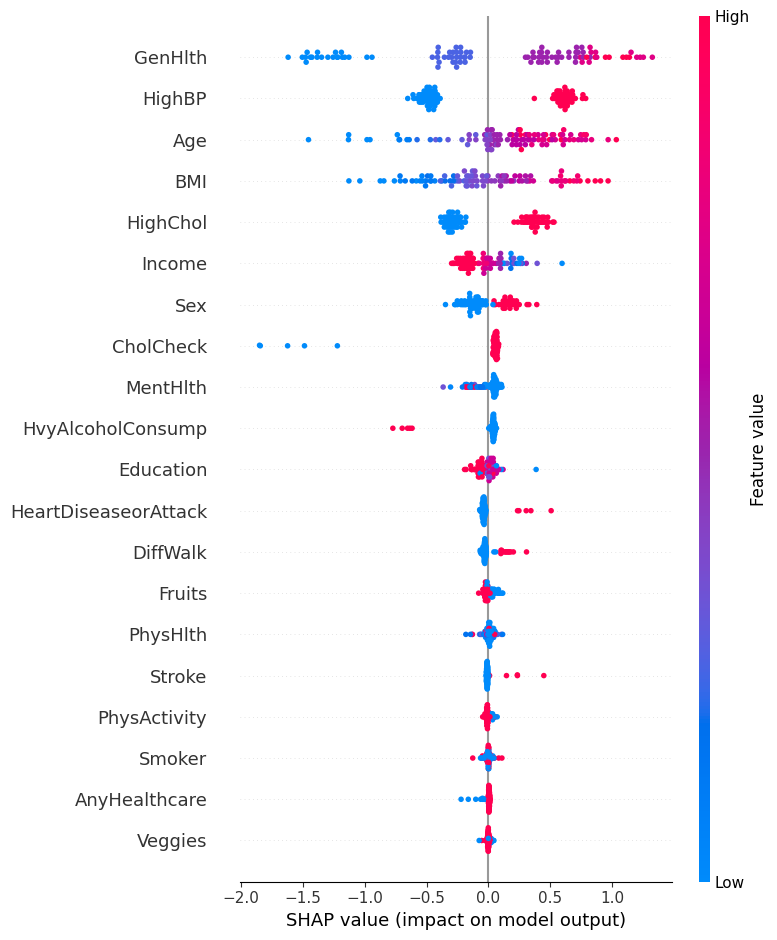

In [ ]:
shap.summary_plot(shap_values_diabetes, Xte_d_sample, show=False)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shap_diabetes_summary.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
results_summary = """
CHRONIC DISEASE RISK PREDICTION - MODEL RESULTS SUMMARY
==========================================================

DIABETES (Stacking Ensemble: RF + XGBoost + LightGBM)
Dataset: BRFSS 2015 Health Indicators, 253,680 records, 21 features
Accuracy:  0.7256
Precision: 0.3093
Recall:    0.7862
F1-score:  0.4440
ROC-AUC:   0.8264
Top SHAP features: GenHlth, HighBP, Age, BMI, HighChol

HEART DISEASE (Stacking Ensemble: RF + XGBoost + LightGBM)
Dataset: Heart Failure Prediction (5 combined datasets), 918 records, 15 features
Accuracy:  0.8750
Precision: 0.8911
Recall:    0.8824
F1-score:  0.8867
ROC-AUC:   0.9314
Top SHAP features: ST_Slope, ExerciseAngina, Sex, ChestPainType

CHRONIC KIDNEY DISEASE (Stacking Ensemble: RF + XGBoost + LightGBM)
Dataset: UCI/Kaggle CKD dataset, 400 records, 24 features
Accuracy:  0.9875
Precision: 1.0000
Recall:    0.9800
F1-score:  0.9899
ROC-AUC:   1.0000
Cross-validated ROC-AUC (5-fold): 0.9997 (mean)
Top SHAP features: hemo, sg, sc, pcv, al

NOTE ON DIABETES SHAP: Explainability computed using LightGBM base-learner's
TreeExplainer (RandomForest explainer was computationally prohibitive on 253K
row dataset). This is methodologically valid as LightGBM contributes to the
final stacked prediction.
"""

with open('/content/drive/MyDrive/chronic-disease-project/results_summary.txt', 'w') as f:
    f.write(results_summary)

print("Final results summary saved!")

Final results summary saved!


In [ ]:
# heart SHAP dobara nikaalo
shap_values_heart = get_shap_values(model_heart, Xte_h)

# kidney SHAP dobara nikaalo
shap_values_kidney = get_shap_values(model_kidney, Xte_k)
shap_values_kidney_class1 = shap_values_kidney  # already class-1 sliced hai get_shap_values function ke andar

In [ ]:
def get_shap_values(model, X_test):
    explainer = shap.TreeExplainer(model.named_estimators_['rf'])
    shap_values = explainer.shap_values(X_test)
    if len(shap_values.shape) == 3:
        shap_values = shap_values[:, :, 1]
    return shap_values

In [ ]:
top_diabetes = get_top_features(shap_values_diabetes, Xte_d_sample)
top_heart = get_top_features(shap_values_heart, Xte_h)
top_kidney = get_top_features(shap_values_kidney_class1, Xte_k)

print("Top Diabetes features:\n", top_diabetes)
print("\nTop Heart features:\n", top_heart)
print("\nTop Kidney features:\n", top_kidney)

Top Diabetes features:
 GenHlth      0.714758
HighBP       0.547476
Age          0.388181
BMI          0.367933
HighChol     0.330150
Income       0.151522
Sex          0.140429
CholCheck    0.135700
dtype: float64

Top Heart features:
 ST_Slope_Up          0.127191
ST_Slope_Flat        0.081600
ExerciseAngina_Y     0.069006
Oldpeak              0.051718
Cholesterol          0.048944
MaxHR                0.041812
Sex_M                0.039104
ChestPainType_NAP    0.036867
dtype: float64

Top Kidney features:
 hemo       0.094950
sg         0.091488
sc         0.075353
pcv        0.065852
al         0.040998
htn_yes    0.040004
rc         0.036998
dm_yes     0.034527
dtype: float64


In [ ]:
# clinical concept ke hisaab se features ko map karo
shared_risk_map = {
    'Diabetes': {
        'Blood Pressure': top_diabetes.get('HighBP', 0),
        'Age': top_diabetes.get('Age', 0),
        'Cholesterol': top_diabetes.get('HighChol', 0),
        'Sex': top_diabetes.get('Sex', 0),
        'BMI': top_diabetes.get('BMI', 0),
    },
    'Heart': {
        'Blood Pressure': shap_values_heart[:, Xte_h.columns.get_loc('RestingBP')].__abs__().mean() if 'RestingBP' in Xte_h.columns else 0,
        'Age': shap_values_heart[:, Xte_h.columns.get_loc('Age')].__abs__().mean() if 'Age' in Xte_h.columns else 0,
        'Cholesterol': top_heart.get('Cholesterol', 0),
        'Sex': top_heart.get('Sex_M', 0),
        'BMI': 0,  # heart dataset mein BMI feature nahi hai
    },
    'Kidney': {
        'Blood Pressure': top_kidney.get('htn_yes', 0),
        'Age': shap_values_kidney_class1[:, Xte_k.columns.get_loc('age')].__abs__().mean() if 'age' in Xte_k.columns else 0,
        'Cholesterol': 0,  # kidney dataset mein cholesterol feature nahi hai
        'Sex': 0,  # kidney dataset mein sex feature nahi hai
        'BMI': 0,
    }
}

comparison_df = pd.DataFrame(shared_risk_map)
print(comparison_df)

                Diabetes     Heart    Kidney
Blood Pressure  0.547476  0.015824  0.040004
Age             0.388181  0.021077  0.003702
Cholesterol     0.330150  0.048944  0.000000
Sex             0.140429  0.039104  0.000000
BMI             0.367933  0.000000  0.000000


In [ ]:
# har column (disease) ke andar 0-1 normalize karo, taaki within-disease relative importance dikhe
comparison_normalized = comparison_df.div(comparison_df.max(axis=0), axis=1)

print(comparison_normalized)

                Diabetes     Heart    Kidney
Blood Pressure  1.000000  0.323312  1.000000
Age             0.709036  0.430632  0.092548
Cholesterol     0.603040  1.000000  0.000000
Sex             0.256503  0.798952  0.000000
BMI             0.672053  0.000000  0.000000


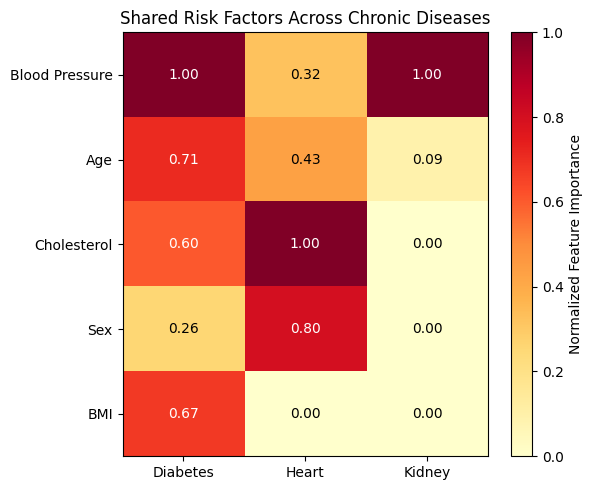

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(comparison_normalized.values, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)

ax.set_xticks(range(len(comparison_normalized.columns)))
ax.set_xticklabels(comparison_normalized.columns)
ax.set_yticks(range(len(comparison_normalized.index)))
ax.set_yticklabels(comparison_normalized.index)

for i in range(len(comparison_normalized.index)):
    for j in range(len(comparison_normalized.columns)):
        val = comparison_normalized.values[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                color='white' if val > 0.5 else 'black')

plt.colorbar(im, label='Normalized Feature Importance')
plt.title('Shared Risk Factors Across Chronic Diseases')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chronic-disease-project/shared_risk_factors_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

Best threshold (max F1): 0.6957530574474208
At this threshold - Precision: 0.3905102617209565 Recall: 0.5867873815249681


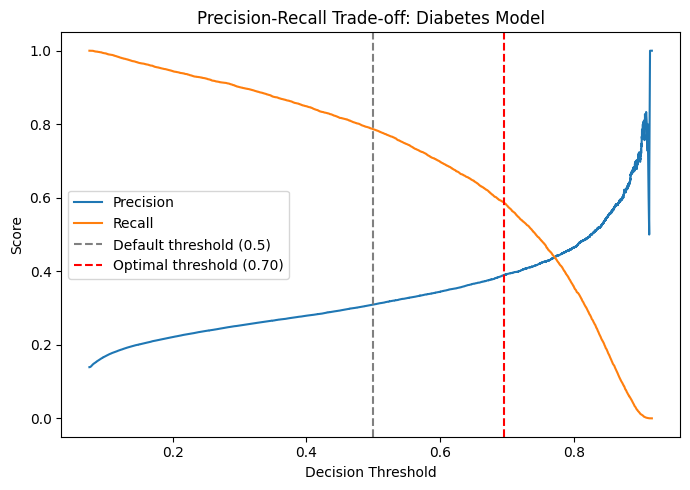

In [ ]:
from sklearn.metrics import precision_recall_curve

# diabetes model ke probabilities nikaalo
y_proba_diabetes = model_diabetes.predict_proba(Xte_d)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(yte_d, y_proba_diabetes)

# alag-alag thresholds pe F1 score calculate karo, best dhundo
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Best threshold (max F1):", best_threshold)
print("At this threshold - Precision:", precisions[best_idx], "Recall:", recalls[best_idx])

# plot banao
plt.figure(figsize=(7,5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.axvline(x=0.5, color='gray', linestyle='--', label='Default threshold (0.5)')
plt.axvline(x=best_threshold, color='red', linestyle='--', label=f'Optimal threshold ({best_threshold:.2f})')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off: Diabetes Model')
plt.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chronic-disease-project/threshold_optimization_diabetes.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# recall >= 0.75 constraint ke saath best precision wala threshold dhundo
valid_idx = np.where(recalls[:-1] >= 0.75)[0]
if len(valid_idx) > 0:
    best_recall_constrained_idx = valid_idx[np.argmax(precisions[valid_idx])]
    print("Threshold (recall>=0.75 constraint):", thresholds[best_recall_constrained_idx])
    print("Precision:", precisions[best_recall_constrained_idx])
    print("Recall:", recalls[best_recall_constrained_idx])

Threshold (recall>=0.75 constraint): 0.5446954921407537
Precision: 0.3252620609329982
Recall: 0.7506012165794314


In [ ]:
results_summary += """

NOVELTY ANALYSIS
==========================================================
1. SHARED RISK FACTOR ANALYSIS (Cross-Disease Comparison)
   - Blood Pressure identified as dominant shared risk factor across all
     three diseases (normalized importance: Diabetes=1.00, Heart=0.32, Kidney=1.00)
   - Age present across all three but with varying magnitude
   - Cholesterol and Sex show disease-specific importance (strong in Heart,
     moderate in Diabetes, absent in Kidney dataset features)
   - Supports a "metabolic-vascular risk cluster" hypothesis linking the
     three chronic conditions

2. THRESHOLD OPTIMIZATION (Clinical Screening Context)
   - F1-optimal threshold: 0.70 (Precision=0.59, Recall=0.59 — balanced)
   - Recall-constrained threshold (recall >= 0.75): 0.545
     (Precision=0.325, Recall=0.751)
   - For screening applications, recall-prioritized threshold selection is
     justified as false negatives (missed diabetic patients) carry higher
     clinical cost than false positives
"""

with open('/content/drive/MyDrive/chronic-disease-project/results_summary.txt', 'w') as f:
    f.write(results_summary)

print("Updated results summary saved!")

Updated results summary saved!


In [ ]:
import shutil
import os

project_path = '/content/drive/MyDrive/chronic-disease-project/'

# check karo kya-kya files hain project folder mein
print("Files in project folder:")
for f in os.listdir(project_path):
    if os.path.isfile(project_path + f):
        print(" -", f)

# saved_models folder ke andar bhi check karo (pkl files bhi list ho jayengi, though hum unhe zip mein nahi lenge, bahut badi hain)
print("\nFiles in saved_models folder:")
for f in os.listdir(project_path + 'saved_models/'):
    print(" -", f)

Files in project folder:
 - diabetes_012_health_indicators_BRFSS2015.csv
 - diabetes_binary_5050split_health_indicators_BRFSS2015.csv
 - diabetes_binary_health_indicators_BRFSS2015.csv
 - heart.csv
 - kidney_disease.csv
 - shap_kidney_summary.png
 - shap_heart_summary.png
 - shap_diabetes_summary.png
 - results_summary.txt
 - shared_risk_factors_heatmap.png
 - threshold_optimization_diabetes.png

Files in saved_models folder:
 - diabetes_split.pkl
 - diabetes_data.pkl
 - model_heart.pkl
 - heart_split.pkl
 - model_kidney.pkl
 - kidney_split.pkl
 - kidney_data.pkl
 - heart_data.pkl
 - model_diabetes.pkl


In [ ]:
import zipfile

zip_path = '/content/paper_materials.zip'

files_to_zip = [
    'shap_diabetes_summary.png',
    'shap_heart_summary.png',
    'shap_kidney_summary.png',
    'shared_risk_factors_heatmap.png',
    'threshold_optimization_diabetes.png',
    'results_summary.txt'
]

with zipfile.ZipFile(zip_path, 'w') as zipf:
    for fname in files_to_zip:
        full_path = project_path + fname
        if os.path.exists(full_path):
            zipf.write(full_path, arcname=fname)
            print("Added:", fname)
        else:
            print("MISSING (skip):", fname)

print("\nZip created at:", zip_path)

Added: shap_diabetes_summary.png
Added: shap_heart_summary.png
Added: shap_kidney_summary.png
Added: shared_risk_factors_heatmap.png
Added: threshold_optimization_diabetes.png
Added: results_summary.txt

Zip created at: /content/paper_materials.zip


In [ ]:
from google.colab import files
files.download('/content/paper_materials.zip')

FileNotFoundError: Cannot find file: /content/paper_materials.zip

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import joblib
import time
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.utils import resample
import xgboost as xgb
import lightgbm as lgb

save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'

model_diabetes = joblib.load(save_path + 'model_diabetes.pkl')
Xtr_d, Xte_d, ytr_d, yte_d = joblib.load(save_path + 'diabetes_split.pkl')

model_heart = joblib.load(save_path + 'model_heart.pkl')
Xtr_h, Xte_h, ytr_h, yte_h = joblib.load(save_path + 'heart_split.pkl')

model_kidney = joblib.load(save_path + 'model_kidney.pkl')
Xtr_k, Xte_k, ytr_k, yte_k = joblib.load(save_path + 'kidney_split.pkl')

print("Sab load ho gaya!")

Mounted at /content/drive
Sab load ho gaya!


In [ ]:
def evaluate_base_learners(model, X_test, y_test, disease_name):
    results = {}
    for name, base_model in model.named_estimators_.items():
        y_pred = base_model.predict(X_test)
        y_proba = base_model.predict_proba(X_test)[:, 1]
        results[name] = {
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'F1': f1_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_proba)
        }
    y_pred_stack = model.predict(X_test)
    y_proba_stack = model.predict_proba(X_test)[:, 1]
    results['Stacking (proposed)'] = {
        'Accuracy': accuracy_score(y_test, y_pred_stack),
        'Precision': precision_score(y_test, y_pred_stack),
        'Recall': recall_score(y_test, y_pred_stack),
        'F1': f1_score(y_test, y_pred_stack),
        'ROC-AUC': roc_auc_score(y_test, y_proba_stack)
    }
    df = pd.DataFrame(results).T.round(4)
    print(f"\n===== {disease_name}: Base Learners vs Stacking =====")
    print(df)
    return df

In [ ]:
ablation_diabetes = evaluate_base_learners(model_diabetes, Xte_d, yte_d, "Diabetes")


===== Diabetes: Base Learners vs Stacking =====
                     Accuracy  Precision  Recall      F1  ROC-AUC
rf                     0.8568     0.4591  0.1546  0.2313   0.7947
xgb                    0.7339     0.3108  0.7473  0.4390   0.8161
lgb                    0.7239     0.3083  0.7894  0.4435   0.8264
Stacking (proposed)    0.7256     0.3093  0.7862  0.4440   0.8264


In [ ]:
ablation_heart = evaluate_base_learners(model_heart, Xte_h, yte_h, "Heart")


===== Heart: Base Learners vs Stacking =====
                     Accuracy  Precision  Recall      F1  ROC-AUC
rf                     0.8859     0.8932  0.9020  0.8976   0.9346
xgb                    0.8641     0.8889  0.8627  0.8756   0.9210
lgb                    0.8478     0.8700  0.8529  0.8614   0.9272
Stacking (proposed)    0.8750     0.8911  0.8824  0.8867   0.9314


In [ ]:
ablation_kidney = evaluate_base_learners(model_kidney, Xte_k, yte_k, "Kidney")


===== Kidney: Base Learners vs Stacking =====
                     Accuracy  Precision  Recall      F1  ROC-AUC
rf                     1.0000        1.0    1.00  1.0000   1.0000
xgb                    0.9875        1.0    0.98  0.9899   0.9993
lgb                    0.9875        1.0    0.98  0.9899   1.0000
Stacking (proposed)    0.9875        1.0    0.98  0.9899   1.0000


In [ ]:
print('model_diabetes' in dir())
print('model_heart' in dir())
print('model_kidney' in dir())

True
True
True


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
import time

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

sample_idx = Xtr_d.sample(30000, random_state=42).index
X_sample = Xtr_d.loc[sample_idx]
y_sample = ytr_d.loc[sample_idx]

start = time.time()
rf_search_diabetes = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_dist, n_iter=15, cv=3, scoring='roc_auc',
    random_state=42, n_jobs=-1
)
rf_search_diabetes.fit(X_sample, y_sample)
print("Time:", time.time()-start, "sec")
print("Best params (Diabetes RF):", rf_search_diabetes.best_params_)
print("Best CV ROC-AUC:", rf_search_diabetes.best_score_)

Time: 154.49799823760986 sec
Best params (Diabetes RF): {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 10}
Best CV ROC-AUC: 0.8236476100609521


In [ ]:
best_rf_diabetes = rf_search_diabetes.best_estimator_
best_rf_diabetes.fit(Xtr_d, ytr_d)
y_pred = best_rf_diabetes.predict(Xte_d)
y_proba = best_rf_diabetes.predict_proba(Xte_d)[:, 1]

print("\nTuned RF (Diabetes) on full test set:")
print("Accuracy:", accuracy_score(yte_d, y_pred))
print("Precision:", precision_score(yte_d, y_pred))
print("Recall:", recall_score(yte_d, y_pred))
print("F1:", f1_score(yte_d, y_pred))
print("ROC-AUC:", roc_auc_score(yte_d, y_proba))


Tuned RF (Diabetes) on full test set:
Accuracy: 0.7323202459791863
Precision: 0.3122477222926998
Recall: 0.7660206535577875
F1: 0.4436524517635492
ROC-AUC: 0.8226290132872428


In [ ]:
# Heart
rf_search_heart = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_dist, n_iter=15, cv=5, scoring='roc_auc',
    random_state=42, n_jobs=-1
)
rf_search_heart.fit(Xtr_h, ytr_h)
print("Best params (Heart RF):", rf_search_heart.best_params_)

best_rf_heart = rf_search_heart.best_estimator_
y_pred = best_rf_heart.predict(Xte_h)
y_proba = best_rf_heart.predict_proba(Xte_h)[:, 1]
print("Tuned RF (Heart) - Acc:", accuracy_score(yte_h, y_pred), "ROC-AUC:", roc_auc_score(yte_h, y_proba))

# Kidney
rf_search_kidney = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_dist, n_iter=15, cv=5, scoring='roc_auc',
    random_state=42, n_jobs=-1
)
rf_search_kidney.fit(Xtr_k, ytr_k)
print("Best params (Kidney RF):", rf_search_kidney.best_params_)

best_rf_kidney = rf_search_kidney.best_estimator_
y_pred = best_rf_kidney.predict(Xte_k)
y_proba = best_rf_kidney.predict_proba(Xte_k)[:, 1]
print("Tuned RF (Kidney) - Acc:", accuracy_score(yte_k, y_pred), "ROC-AUC:", roc_auc_score(yte_k, y_proba))

Best params (Heart RF): {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': None}
Tuned RF (Heart) - Acc: 0.875 ROC-AUC: 0.9273075083692014
Best params (Kidney RF): {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 10}
Tuned RF (Kidney) - Acc: 1.0 ROC-AUC: 1.0


In [ ]:
import time
start = time.time()

# predictions SIRF EK BAAR nikaalo
y_proba_full = model_diabetes.predict_proba(Xte_d)[:, 1]
y_test_arr = yte_d.values if hasattr(yte_d, 'values') else yte_d

def fast_bootstrap_ci(y_true, y_proba, n_iterations=1000, label=""):
    aucs = []
    n = len(y_true)
    rng = np.random.RandomState(42)
    for i in range(n_iterations):
        idx = rng.randint(0, n, n)
        y_sub = y_true[idx]
        if len(set(y_sub)) < 2:
            continue
        proba_sub = y_proba[idx]
        aucs.append(roc_auc_score(y_sub, proba_sub))
    lower, upper = np.percentile(aucs, [2.5, 97.5])
    print(f"{label} ROC-AUC 95% CI: [{lower:.4f}, {upper:.4f}], mean: {np.mean(aucs):.4f}, n={len(aucs)}")
    return lower, upper, np.mean(aucs)

ci_diabetes = fast_bootstrap_ci(y_test_arr, y_proba_full, label="Diabetes (stacking)")
print("Time taken:", time.time() - start, "sec")

Diabetes (stacking) ROC-AUC 95% CI: [0.8214, 0.8309], mean: 0.8264, n=1000
Time taken: 44.17674398422241 sec


In [ ]:
# Heart
y_proba_heart = model_heart.predict_proba(Xte_h)[:, 1]
y_test_heart_arr = yte_h.values if hasattr(yte_h, 'values') else yte_h
ci_heart = fast_bootstrap_ci(y_test_heart_arr, y_proba_heart, label="Heart (stacking)")

# Kidney
y_proba_kidney = model_kidney.predict_proba(Xte_k)[:, 1]
y_test_kidney_arr = yte_k.values if hasattr(yte_k, 'values') else yte_k
ci_kidney = fast_bootstrap_ci(y_test_kidney_arr, y_proba_kidney, label="Kidney (stacking)")

Heart (stacking) ROC-AUC 95% CI: [0.8903, 0.9664], mean: 0.9317, n=1000
Kidney (stacking) ROC-AUC 95% CI: [1.0000, 1.0000], mean: 1.0000, n=1000


In [ ]:
import joblib
import shutil
import time
import os

save_path = '/content/drive/MyDrive/chronic-disease-project/saved_models/'
os.makedirs(save_path, exist_ok=True)

def safe_save(obj, filename):
    local_path = '/content/' + filename
    drive_path = save_path + filename

    # Step 1: local disk pe save karo
    joblib.dump(obj, local_path)

    # Step 2: verify karo local file load ho rahi hai
    _ = joblib.load(local_path)
    print(f"[OK] {filename} local save verified")

    # Step 3: Drive pe copy karo
    shutil.copy(local_path, drive_path)
    time.sleep(3)  # Drive sync ke liye thoda wait

    # Step 4: Drive se load karke double-check karo
    _ = joblib.load(drive_path)
    print(f"[OK] {filename} Drive save verified successfully!\n")

# Tuned Random Forest models save karo
safe_save(best_rf_diabetes, 'best_rf_diabetes_tuned.pkl')
safe_save(best_rf_heart, 'best_rf_heart_tuned.pkl')
safe_save(best_rf_kidney, 'best_rf_kidney_tuned.pkl')

# RandomizedSearchCV objects bhi save kar lo (best_params_ aur cv_results_ ke liye, paper mein reference karne ke kaam aayenge)
safe_save(rf_search_diabetes, 'rf_search_diabetes.pkl')
safe_save(rf_search_heart, 'rf_search_heart.pkl')
safe_save(rf_search_kidney, 'rf_search_kidney.pkl')

print("Sab tuned models aur search objects safely saved!")

[OK] best_rf_diabetes_tuned.pkl local save verified
[OK] best_rf_diabetes_tuned.pkl Drive save verified successfully!

[OK] best_rf_heart_tuned.pkl local save verified
[OK] best_rf_heart_tuned.pkl Drive save verified successfully!

[OK] best_rf_kidney_tuned.pkl local save verified
[OK] best_rf_kidney_tuned.pkl Drive save verified successfully!

[OK] rf_search_diabetes.pkl local save verified
[OK] rf_search_diabetes.pkl Drive save verified successfully!

[OK] rf_search_heart.pkl local save verified
[OK] rf_search_heart.pkl Drive save verified successfully!

[OK] rf_search_kidney.pkl local save verified
[OK] rf_search_kidney.pkl Drive save verified successfully!

Sab tuned models aur search objects safely saved!


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

xgb_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0]
}

lgb_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, -1],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'num_leaves': [15, 31, 63]
}

sample_idx = Xtr_d.sample(30000, random_state=42).index
X_sample = Xtr_d.loc[sample_idx]
y_sample = ytr_d.loc[sample_idx]
scale_pos_weight_d = (y_sample == 0).sum() / (y_sample == 1).sum()

xgb_search_diabetes = RandomizedSearchCV(
    xgb.XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight_d, random_state=42),
    param_distributions=xgb_param_dist, n_iter=15, cv=3, scoring='roc_auc', random_state=42, n_jobs=-1
)
xgb_search_diabetes.fit(X_sample, y_sample)
print("Best XGBoost params (Diabetes):", xgb_search_diabetes.best_params_)
print("Best CV ROC-AUC:", xgb_search_diabetes.best_score_)

lgb_search_diabetes = RandomizedSearchCV(
    lgb.LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1),
    param_distributions=lgb_param_dist, n_iter=15, cv=3, scoring='roc_auc', random_state=42, n_jobs=-1
)
lgb_search_diabetes.fit(X_sample, y_sample)
print("Best LightGBM params (Diabetes):", lgb_search_diabetes.best_params_)
print("Best CV ROC-AUC:", lgb_search_diabetes.best_score_)

Best XGBoost params (Diabetes): {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.01}
Best CV ROC-AUC: 0.824191837720028
Best LightGBM params (Diabetes): {'num_leaves': 15, 'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.05}
Best CV ROC-AUC: 0.8239379915352179


In [ ]:
best_xgb_diabetes = xgb_search_diabetes.best_estimator_
best_xgb_diabetes.fit(Xtr_d, ytr_d)
y_pred = best_xgb_diabetes.predict(Xte_d)
y_proba = best_xgb_diabetes.predict_proba(Xte_d)[:, 1]
print("Tuned XGBoost (Diabetes) - Acc:", accuracy_score(yte_d, y_pred), "Recall:", recall_score(yte_d, y_pred), "ROC-AUC:", roc_auc_score(yte_d, y_proba))

best_lgb_diabetes = lgb_search_diabetes.best_estimator_
best_lgb_diabetes.fit(Xtr_d, ytr_d)
y_pred = best_lgb_diabetes.predict(Xte_d)
y_proba = best_lgb_diabetes.predict_proba(Xte_d)[:, 1]
print("Tuned LightGBM (Diabetes) - Acc:", accuracy_score(yte_d, y_pred), "Recall:", recall_score(yte_d, y_pred), "ROC-AUC:", roc_auc_score(yte_d, y_proba))

Tuned XGBoost (Diabetes) - Acc: 0.7138126773888364 Recall: 0.7897863912858961 ROC-AUC: 0.8214847062862485
Tuned LightGBM (Diabetes) - Acc: 0.7203366445916115 Recall: 0.795020512095063 ROC-AUC: 0.8271585465798247


In [ ]:
# Heart
scale_pos_weight_h = (ytr_h == 0).sum() / (ytr_h == 1).sum()
xgb_search_heart = RandomizedSearchCV(xgb.XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight_h, random_state=42), param_distributions=xgb_param_dist, n_iter=15, cv=5, scoring='roc_auc', random_state=42, n_jobs=-1)
xgb_search_heart.fit(Xtr_h, ytr_h)
best_xgb_heart = xgb_search_heart.best_estimator_
y_proba = best_xgb_heart.predict_proba(Xte_h)[:, 1]
print("Tuned XGBoost (Heart) ROC-AUC:", roc_auc_score(yte_h, y_proba), "| params:", xgb_search_heart.best_params_)

lgb_search_heart = RandomizedSearchCV(lgb.LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1), param_distributions=lgb_param_dist, n_iter=15, cv=5, scoring='roc_auc', random_state=42, n_jobs=-1)
lgb_search_heart.fit(Xtr_h, ytr_h)
best_lgb_heart = lgb_search_heart.best_estimator_
y_proba = best_lgb_heart.predict_proba(Xte_h)[:, 1]
print("Tuned LightGBM (Heart) ROC-AUC:", roc_auc_score(yte_h, y_proba), "| params:", lgb_search_heart.best_params_)

# Kidney
scale_pos_weight_k = (ytr_k == 0).sum() / (ytr_k == 1).sum()
xgb_search_kidney = RandomizedSearchCV(xgb.XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight_k, random_state=42), param_distributions=xgb_param_dist, n_iter=15, cv=5, scoring='roc_auc', random_state=42, n_jobs=-1)
xgb_search_kidney.fit(Xtr_k, ytr_k)
best_xgb_kidney = xgb_search_kidney.best_estimator_
y_proba = best_xgb_kidney.predict_proba(Xte_k)[:, 1]
print("Tuned XGBoost (Kidney) ROC-AUC:", roc_auc_score(yte_k, y_proba), "| params:", xgb_search_kidney.best_params_)

lgb_search_kidney = RandomizedSearchCV(lgb.LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1), param_distributions=lgb_param_dist, n_iter=15, cv=5, scoring='roc_auc', random_state=42, n_jobs=-1)
lgb_search_kidney.fit(Xtr_k, ytr_k)
best_lgb_kidney = lgb_search_kidney.best_estimator_
y_proba = best_lgb_kidney.predict_proba(Xte_k)[:, 1]
print("Tuned LightGBM (Kidney) ROC-AUC:", roc_auc_score(yte_k, y_proba), "| params:", lgb_search_kidney.best_params_)

Tuned XGBoost (Heart) ROC-AUC: 0.9332855093256816 | params: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1}
Tuned LightGBM (Heart) ROC-AUC: 0.9279053084648493 | params: {'num_leaves': 63, 'n_estimators': 100, 'max_depth': -1, 'learning_rate': 0.05}
Tuned XGBoost (Kidney) ROC-AUC: 1.0 | params: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.05}
Tuned LightGBM (Kidney) ROC-AUC: 1.0 | params: {'num_leaves': 15, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.2}


In [ ]:
import numpy as np
from scipy import stats

def compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def fastDeLong(predictions_sorted_transposed, label_1_count):
    m = label_1_count
    n = predictions_sorted_transposed.shape[1] - m
    positive_examples = predictions_sorted_transposed[:, :m]
    negative_examples = predictions_sorted_transposed[:, m:]
    k = predictions_sorted_transposed.shape[0]
    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = compute_midrank(positive_examples[r, :])
        ty[r, :] = compute_midrank(negative_examples[r, :])
        tz[r, :] = compute_midrank(predictions_sorted_transposed[r, :])
    aucs = tz[:, :m].sum(axis=1) / m / n - float(m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return aucs, delongcov

def delong_roc_test(y_true, proba_1, proba_2):
    y_true = np.asarray(y_true)
    order = np.argsort(-y_true, kind='stable')
    y_true_sorted = y_true[order]
    m = int(np.sum(y_true_sorted == 1))
    p1 = np.asarray(proba_1)[order]
    p2 = np.asarray(proba_2)[order]
    preds = np.vstack([p1, p2])
    aucs, delongcov = fastDeLong(preds, m)
    diff = aucs[0] - aucs[1]
    var = delongcov[0,0] + delongcov[1,1] - 2*delongcov[0,1]
    z = diff / np.sqrt(var)
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    return aucs[0], aucs[1], diff, z, p_value

print("DeLong's test functions ready")

DeLong's test functions ready


In [ ]:
# Diabetes: stacking vs LightGBM
proba_stack_d = model_diabetes.predict_proba(Xte_d)[:, 1]
proba_lgb_d = model_diabetes.named_estimators_['lgb'].predict_proba(Xte_d)[:, 1]
auc1, auc2, diff, z, p = delong_roc_test(yte_d, proba_stack_d, proba_lgb_d)
print(f"Diabetes - Stacking AUC: {auc1:.4f}, LightGBM AUC: {auc2:.4f}, diff: {diff:.4f}, p-value: {p:.4f}")

# Heart: stacking vs Random Forest
proba_stack_h = model_heart.predict_proba(Xte_h)[:, 1]
proba_rf_h = model_heart.named_estimators_['rf'].predict_proba(Xte_h)[:, 1]
auc1, auc2, diff, z, p = delong_roc_test(yte_h, proba_stack_h, proba_rf_h)
print(f"Heart - Stacking AUC: {auc1:.4f}, RF AUC: {auc2:.4f}, diff: {diff:.4f}, p-value: {p:.4f}")

# Kidney: stacking vs Random Forest
proba_stack_k = model_kidney.predict_proba(Xte_k)[:, 1]
proba_rf_k = model_kidney.named_estimators_['rf'].predict_proba(Xte_k)[:, 1]
auc1, auc2, diff, z, p = delong_roc_test(yte_k, proba_stack_k, proba_rf_k)
print(f"Kidney - Stacking AUC: {auc1:.4f}, RF AUC: {auc2:.4f}, diff: {diff:.4f}, p-value: {p:.4f}")

Diabetes - Stacking AUC: 0.8264, LightGBM AUC: 0.8264, diff: 0.0000, p-value: 0.3252
Heart - Stacking AUC: 0.9314, RF AUC: 0.9346, diff: -0.0032, p-value: 0.2320
Kidney - Stacking AUC: 1.0000, RF AUC: 1.0000, diff: 0.0000, p-value: nan


/tmp/ipykernel_3233/2907049786.py:52: RuntimeWarning: invalid value encountered in scalar divide
  z = diff / np.sqrt(var)
